# Zielwert THG – zeitbezogene Ableitung nationaler CO₂-Budgets

**Wissenschaftliche, ausführbare Methodendokumentation · Version 0.2.0 · Stand 11.11.2026**

Dieses Notebook führt die nationalen Klimabudgets über explizite **Referenzjahre**, **historische Emissionsabzüge** und **Bewertungsjahre** zu flächenbezogenen THG-Zielwerten für Plusenergiequartiere. Die Berechnung erfolgt sequentiell; Tabellen und Abbildungen sind Teil der Forschungsdokumentation, kein Dashboard.

**Zwei getrennte Rechnungen:** (A) historische Herleitung gemäß Schneider et al. (2025) / Steininger et al. (2022), mit Reproduktion von L3 = 320, und Dokumentation der Overshoot-Alternative; (B) Lamboll et al. (2023), Referenzjahr 2023 → Bewertungen 2025 und 2026, sobald eine für Österreich allokierte CO₂-Budgetreihe und kompatible Emissionsjahre vorliegen. Fehlende Daten unterbrechen ausschließlich die betroffene Rechnung, ohne Ersatzwerte zu erfinden.

### FAIR-Umsetzung

| Prinzip | Umsetzung |
|---|---|
| **Findable** | Tabellen mit eindeutigen `budget_id`, `quelle_id`, DOI und Versionskennung |
| **Accessible** | Jupyter-Notebook und offen lesbare CSV-Tabellen, dokumentierte fehlende Werte |
| **Interoperable** | Spaltenbezeichnungen, Einheiten (`Mt CO2`, `Mt CO2e`, `Gt CO2`), Referenzjahr und Zeitgrenzen explizit |
| **Reusable** | Deterministische Funktionen, Szenario-Parameter, Validierungen, Versionen, reproduzierbarer Export |

**Definition des Bewertungsjahrs** `y`: Das verbleibende Budget **ab Beginn von Jahr y** ergibt sich nach Abzug der tatsächlichen Emissionen aus den vollständigen Jahren `referenzjahr` bis `y − 1`. Somit verwendet 2025 die Jahre 2022–2024 und 2026 zusätzlich 2025. Der Beginn eines Budgetjahrs ist nicht mit dem Publikationsdatum zu verwechseln.

## 1. Quellenregister, Gase und Bilanzgrenzen

- **S1** Schneider et al. (2025), *Declaration-Ready Climate-Neutral PEDs*, [DOI 10.3390/designs9060123](https://doi.org/10.3390/designs9060123), Abschn. 2.3, Tabelle 2 und Tabelle A1. Budgetzahlen ab 2022, historische Reproduktion 2025.
- **S5** Steininger et al. (2022), *Sharing the effort of the European Green Deal among countries*, [DOI 10.1038/s41467-022-31204-8](https://doi.org/10.1038/s41467-022-31204-8), Herleitungsquelle der ursprünglichen nationalen Budgetzuordnung laut S1.
- **S6** Lamboll et al. (2023), *Assessing the size and uncertainty of remaining carbon budgets*, [DOI 10.1038/s41558-023-01848-5](https://doi.org/10.1038/s41558-023-01848-5), globale Budgets ab Januar 2023. Eine **zusätzliche, offenzulegende nationale Allokation** ist nötig, bevor diese als AT-Budget verwendet werden dürfen.
- **S7** Umweltbundesamt (2026), *Austria’s Annual Greenhouse Gas Inventory 1990–2024*, REP-1016, [PDF](https://www.umweltbundesamt.at/fileadmin/site/publikationen/rep1016.pdf), Tabelle 2 (S. 11 des Berichts) und Anhang I, Tabelle A.I-1. Die hier eingetragenen Jahresdaten sind **Gesamt-THG ohne LULUCF in CO₂e**, nicht CO₂ allein.
- **S8** Umweltbundesamt (02.09.2026), [Nahzeitprognose THG-Emissionen 2025](https://www.umweltbundesamt.at/news260902-treibhausgas-emissionen-2025): **67,1 Mt CO₂e**, vorläufig (nicht CO₂-only).
- **S2** beigefügtes `03-zielwert-thg.qmd`, Flächenabgrenzung, 50-jährige Lebenszyklusbetrachtung und weitere Bilanzregeln.
- **S4** Amann et al. (2021), *Kapazitätsanpassung der Bauwirtschaft*, historische Bezugsfläche von 906,7 Mio. m² BGF in S1.

**Wichtige Abgrenzung:** Ein physisches CO₂-Restbudget (`Mt CO₂`) muss um **CO₂-Emissionen** reduziert werden. Die amtliche Gesamt-THG-Reihe (`Mt CO₂e`) wird hier zum Quellenvergleich geführt und bei CO₂-only-Abzügen ausdrücklich *nicht* eingesetzt. Der historische S1-Abzug von 150 Mt ist eine aus Tabelle A1 abgeleitete **publikationsspezifische aggregierte Annahme**; er wird nicht als aktuelles Inventarergebnis ausgegeben. Eine Änderung auf revidierte Inventardaten ist eine eigene Rekalibrierung.

In [1]:
from __future__ import annotations
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path
import csv, hashlib, json, sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 105)
plt.rcParams.update({'figure.figsize': (9, 4.4), 'axes.grid': True, 'grid.alpha': .22, 'font.size': 10})
MODEL_VERSION = '0.2.0'
SOURCE_URLS = {'S1': 'https://doi.org/10.3390/designs9060123',
               'S5': 'https://doi.org/10.1038/s41467-022-31204-8',
               'S6': 'https://doi.org/10.1038/s41558-023-01848-5',
               'S7': 'https://www.umweltbundesamt.at/fileadmin/site/publikationen/rep1016.pdf',
               'S8': 'https://www.umweltbundesamt.at/news260902-treibhausgas-emissionen-2025'}
print(f'Methodenversion {MODEL_VERSION} | Python {sys.version.split()[0]} | pandas {pd.__version__}')

Methodenversion 0.2.0 | Python 3.13.5 | pandas 2.2.3


## 2. Quelldaten als eigenständige, bearbeitbare Tabellen

**Dateien im selben Ordner wie das Notebook:**

| Datei | Zweck | Datentyp |
|---|---|---|
| `thg_nationale_klimabudgets.csv` | Nationale Szenariobudgets inkl. **Referenzjahr** | Mt CO₂, Österreich |
| `thg_historische_emissionen_AT.csv` | Historische Emissionen **pro Kalenderjahr** | CO₂-only bzw. getrennt THG-CO₂e |
| `thg_historische_aggregatannahmen.csv` | Historischer pauschaler Abzug zur exakten Referenzreproduktion | Mt CO₂, Zeitraum 2022–2024 |
| `thg_globale_budgets_kontext.csv` | Lamboll 2023 **globale**, nicht bereits nationale Budgets | Gt CO₂ |

Die übergebenen Dateien werden bevorzugt eingelesen. Ein vollständig sichtbarer eingebetteter Basisdatenstand erlaubt die Ausführung des Notebooks auch ohne CSV-Dateien; beim Lesen wird gemeldet, welche Datenquelle verwendet wurde. Änderungen an der CSV sind für wissenschaftliche Versionskontrolle vorzuziehen. Leere Werte bedeuten **unbekannt**, niemals null.

In [2]:
SEED_BUDGETS = [{'budget_id': 'STEIN2022_15_NO_50', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'ohne', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2022, 'national_budget_Mt': 510, 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert'}, {'budget_id': 'STEIN2022_15_NO_66', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'ohne', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2022, 'national_budget_Mt': 280, 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert: L3-Referenz'}, {'budget_id': 'STEIN2022_15_YES_50', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'mit', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2022, 'national_budget_Mt': 610, 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert'}, {'budget_id': 'STEIN2022_15_YES_66', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'mit', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2022, 'national_budget_Mt': 340, 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert'}, {'budget_id': 'LAMBOLL2023_AT_15_50', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '1,5 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}, {'budget_id': 'LAMBOLL2023_AT_15_66', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '1,5 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}, {'budget_id': 'LAMBOLL2023_AT_20_50', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '2,0 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}, {'budget_id': 'LAMBOLL2023_AT_20_66', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '2,0 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}]
SEED_HIST = [{'jahr': 2022, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 73.506582, 'einheit': 'Mt CO2e', 'quelle_id': 'S7', 'datenversion': 'Inventar 2026 (revidiert)', 'abgrenzung': 'ohne LULUCF, gesamte THG', 'datenstatus': 'kontext: NICHT CO2-Budget-kompatibel'}, {'jahr': 2023, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 68.67406, 'einheit': 'Mt CO2e', 'quelle_id': 'S7', 'datenversion': 'Inventar 2026 (revidiert)', 'abgrenzung': 'ohne LULUCF, gesamte THG', 'datenstatus': 'kontext: NICHT CO2-Budget-kompatibel'}, {'jahr': 2024, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 66.637831, 'einheit': 'Mt CO2e', 'quelle_id': 'S7', 'datenversion': 'Inventar 2026 (revidiert)', 'abgrenzung': 'ohne LULUCF, gesamte THG', 'datenstatus': 'kontext: NICHT CO2-Budget-kompatibel'}, {'jahr': 2025, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 67.1, 'einheit': 'Mt CO2e', 'quelle_id': 'S8', 'datenversion': 'NowCast September 2026', 'abgrenzung': 'ohne LULUCF, THG', 'datenstatus': 'vorläufig; NICHT CO2-Budget-kompatibel'}, {'jahr': 2022, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': 'S7', 'datenversion': 'Nachtrag erforderlich', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; CO2-Jahreswert fehlt'}, {'jahr': 2023, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': 'S7', 'datenversion': 'Nachtrag erforderlich', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; CO2-Jahreswert fehlt'}, {'jahr': 2024, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': 'S7', 'datenversion': 'Nachtrag erforderlich', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; CO2-Jahreswert fehlt'}, {'jahr': 2025, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': '', 'datenversion': 'Noch keine harmonisierte Reihe übernommen', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; für 2026-Budget notwendig'}]
SEED_AGG = [{'von_jahr': 2022, 'bis_jahr': 2024, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': 150.0, 'einheit': 'Mt CO2', 'quelle_id': 'S1-A1', 'herleitung': 'Schneider et al. 2025, Tab. A1: 280-130 bzw. 340-190', 'hinweis': 'aggregierte historische Abzugsannahme; keine jährliche Inventarreihe'}]
SEED_GLOBAL = [{'quelle': 'Lamboll 2023', 'temperatur': '1,5 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 250, 'einheit': 'Gt CO2', 'quelle_id': 'S6', 'hinweis': 'global, keine nationale Allokation'}, {'quelle': 'Lamboll 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 1220, 'einheit': 'Gt CO2', 'quelle_id': 'S6', 'hinweis': 'global, kein AT-Budget; Paper nennt ca. 1200'}, {'quelle': 'Lamboll 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2023, 'global_budget_Gt': 940, 'einheit': 'Gt CO2', 'quelle_id': 'S6', 'hinweis': 'global, keine nationale Allokation'}]

def read_fair_csv(filename: str, fallback: list[dict]) -> pd.DataFrame:
    p = Path(filename)
    if p.is_file():
        frame = pd.read_csv(p, encoding='utf-8', dtype={'budget_id': str, 'quelle_id': str})
        print('CSV:', p)
    else:
        frame = pd.DataFrame(fallback)
        print('EINGEBETTETE KOPIE (CSV fehlt):', filename)
    return frame.replace('', np.nan)

budgets = read_fair_csv('thg_nationale_klimabudgets.csv', SEED_BUDGETS)
history = read_fair_csv('thg_historische_emissionen_AT.csv', SEED_HIST)
aggregates = read_fair_csv('thg_historische_aggregatannahmen.csv', SEED_AGG)
global_budgets = read_fair_csv('thg_globale_budgets_kontext.csv', SEED_GLOBAL)
for col in ['wahrscheinlichkeit_pct','referenzjahr','national_budget_Mt']:
    budgets[col] = pd.to_numeric(budgets[col], errors='coerce')
for col in ['jahr','emissionen_Mt']:
    history[col] = pd.to_numeric(history[col], errors='coerce')
for col in ['von_jahr','bis_jahr','emissionen_Mt']:
    aggregates[col] = pd.to_numeric(aggregates[col], errors='coerce')
assert budgets.budget_id.is_unique
assert not history.duplicated(['jahr','reihe']).any()
assert budgets.referenzjahr.notna().all()
assert budgets.einheit.eq('Mt CO2').all(), 'Die nationalen Budgeteinträge müssen in Mt CO2 stehen.'
assert budgets.loc[budgets.national_budget_Mt.notna(), 'national_budget_Mt'].ge(0).all()
display(budgets[['budget_id','temperatur','overshoot','wahrscheinlichkeit_pct','referenzjahr','national_budget_Mt','datenstatus']])

CSV: thg_nationale_klimabudgets.csv
CSV: thg_historische_emissionen_AT.csv
CSV: thg_historische_aggregatannahmen.csv
CSV: thg_globale_budgets_kontext.csv


,budget_id,temperatur,overshoot,wahrscheinlichkeit_pct,referenzjahr,national_budget_Mt,datenstatus
0,STEIN2022_15_NO_50,"1,5 °C",ohne,50,2022,510.0,publiziert
1,STEIN2022_15_NO_66,"1,5 °C",ohne,66,2022,280.0,publiziert: L3-Referenz
2,STEIN2022_15_YES_50,"1,5 °C",mit,50,2022,610.0,publiziert
3,STEIN2022_15_YES_66,"1,5 °C",mit,66,2022,340.0,publiziert
4,LAMBOLL2023_AT_15_50,"1,5 °C",nicht festgelegt,50,2023,NaN,offen: nationales Budget fehlt
5,LAMBOLL2023_AT_15_66,"1,5 °C",nicht festgelegt,66,2023,NaN,offen: nationales Budget fehlt
6,LAMBOLL2023_AT_20_50,"2,0 °C",nicht festgelegt,50,2023,NaN,offen: nationales Budget fehlt
7,LAMBOLL2023_AT_20_66,"2,0 °C",nicht festgelegt,66,2023,NaN,offen: nationales Budget fehlt


### 2.1 Globale Lamboll-Budgets sind kein österreichischer Sektorwert

Der von Lamboll et al. (2023) genannte Wert von rund **1.200 Gt CO₂ für 2 °C und 50 %** betrifft die **Welt** ab Januar 2023 (präzise Schätzung im Text ca. 1.220 Gt). Er darf nicht als `1.200 Mt` oder `1.000 Mt` für Österreich in die folgende Allokationsformel eingesetzt werden. Für den neuen österreichischen Lauf sind ein eigenes nationales Budget, der Allokationsschlüssel, die Systemgrenze und die Wahrscheinlichkeit nachzutragen. Angaben zu **temporärem Overshoot** im Sinn der ursprünglichen Steininger-Varianten sind für Lamboll hier nicht automatisch vergleichbar.

In [3]:
display(global_budgets)
print('Hinweis: Die obigen Gt-Werte werden NICHT in der nationalen Berechnung verwendet.')

,quelle,temperatur,wahrscheinlichkeit_pct,referenzjahr,global_budget_Gt,einheit,quelle_id,hinweis
0,Lamboll 2023,"1,5 °C",50,2023,250,Gt CO2,S6,"global, keine nationale Allokation"
1,Lamboll 2023,"2,0 °C",50,2023,1220,Gt CO2,S6,"global, kein AT-Budget; Paper nennt ca. 1200"
2,Lamboll 2023,"2,0 °C",66,2023,940,Gt CO2,S6,"global, keine nationale Allokation"


Hinweis: Die obigen Gt-Werte werden NICHT in der nationalen Berechnung verwendet.


### 2.2 Jahresinventar und historische, aggregierte Publikationsannahme

Die jährlichen Gesamt-THG-Werte für 2022–2024 stammen aus der revidierten österreichischen Inventur 2026, der Wert für 2025 aus einem NowCast. Alle sind **CO₂e**. Für eine CO₂-only-Fortschreibung bleiben die entsprechenden Zellen der Reihe `CO2_TERRITORIAL` offen. Die aggregierte S1-Annahme von **150 Mt CO₂ für 2022–2024** erlaubt ausschließlich die exakte Publikationsreproduktion; sie wird als eigener Datenstand geführt, damit keine scheinbare Jahresverteilung auf 2022, 2023 und 2024 erfunden wird.

,jahr,reihe,emissionen_Mt,einheit,quelle_id,datenversion,abgrenzung,datenstatus
0,2022,CO2_TERRITORIAL,NaN,Mt CO2,S7,Nachtrag erforderlich,"CO2-only, territorial, LULUCF-Konvention prüfen",offen; CO2-Jahreswert fehlt
1,2023,CO2_TERRITORIAL,NaN,Mt CO2,S7,Nachtrag erforderlich,"CO2-only, territorial, LULUCF-Konvention prüfen",offen; CO2-Jahreswert fehlt
2,2024,CO2_TERRITORIAL,NaN,Mt CO2,S7,Nachtrag erforderlich,"CO2-only, territorial, LULUCF-Konvention prüfen",offen; CO2-Jahreswert fehlt
3,2025,CO2_TERRITORIAL,NaN,Mt CO2,NaN,Noch keine harmonisierte Reihe übernommen,"CO2-only, territorial, LULUCF-Konvention prüfen",offen; für 2026-Budget notwendig
4,2022,GHG_TOTAL_EXCL_LULUCF,73.506582,Mt CO2e,S7,Inventar 2026 (revidiert),"ohne LULUCF, gesamte THG",kontext: NICHT CO2-Budget-kompatibel
5,2023,GHG_TOTAL_EXCL_LULUCF,68.674060,Mt CO2e,S7,Inventar 2026 (revidiert),"ohne LULUCF, gesamte THG",kontext: NICHT CO2-Budget-kompatibel
6,2024,GHG_TOTAL_EXCL_LULUCF,66.637831,Mt CO2e,S7,Inventar 2026 (revidiert),"ohne LULUCF, gesamte THG",kontext: NICHT CO2-Budget-kompatibel
7,2025,GHG_TOTAL_EXCL_LULUCF,67.100000,Mt CO2e,S8,NowCast September 2026,"ohne LULUCF, THG",vorläufig; NICHT CO2-Budget-kompatibel


,von_jahr,bis_jahr,reihe,emissionen_Mt,einheit,quelle_id,herleitung,hinweis
0,2022,2024,CO2_TERRITORIAL,150.0,Mt CO2,S1-A1,"Schneider et al. 2025, Tab. A1: 280-130 bzw. 340-190",aggregierte historische Abzugsannahme; keine jährliche Inventarreihe


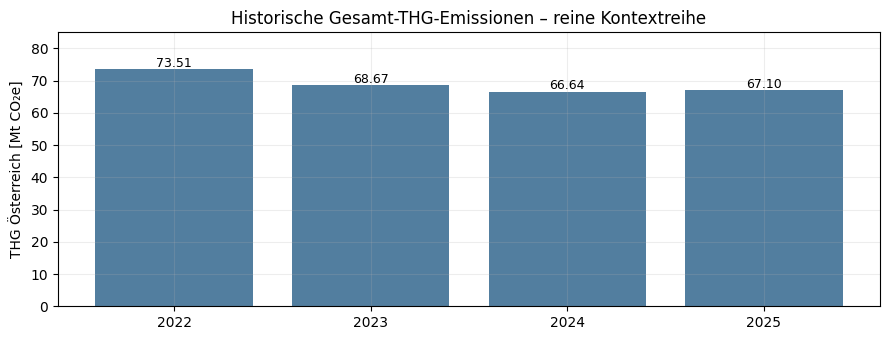

In [4]:
display(history.sort_values(['reihe','jahr']).reset_index(drop=True))
display(aggregates)
fig,ax=plt.subplots(figsize=(9,3.5))
inv=history.loc[history.reihe=='GHG_TOTAL_EXCL_LULUCF'].sort_values('jahr')
ax.bar(inv.jahr.astype(int).astype(str), inv.emissionen_Mt, color='#527e9f')
for i,row in enumerate(inv.itertuples()):
    ax.text(i,row.emissionen_Mt+0.7,f'{row.emissionen_Mt:.2f}',ha='center',fontsize=9)
ax.set(ylabel='THG Österreich [Mt CO₂e]', title='Historische Gesamt-THG-Emissionen – reine Kontextreihe')
ax.set_ylim(0,85)
plt.tight_layout();plt.show()

## 3. Parameter und Auswahl der Rechenstände

Die folgenden Parameter sind die wenigen Stellschrauben. **Das Referenzjahr** wird pro Budgetzeile dokumentiert und kann dort verändert werden; die vorliegende Konvention verlangt die vollständige Jahresreihe **ab diesem Referenzjahr**. `EVALUATION_YEARS` beschreibt die Jahre, zu deren Jahresbeginn das verbleibende Budget ausgewiesen wird.

Für die nationale Senkenannahme gibt es zwei zeitliche Konventionen: `fixed_end` verwendet als Endzeitpunkt 2075, sodass der verbleibende Senkenzeitraum 2025–2075 **50 Jahre** beziehungsweise 2026–2075 **49 Jahre** umfasst. `rolling_50` stellt für jedes neue Bewertungsjahr 50 Jahre an Senken in Ansatz. Die historische Regression verwendet immer 2025–2075 und `fixed_end`.

In [5]:
# ===== WISSENSCHAFTLICHE MODELLPARAMETER =====
EVALUATION_YEARS = [2025, 2026]  # Budgets jeweils am 1.1. des Jahres
SELECTED_BUDGET_ID = 'LAMBOLL2023_AT_20_66'  # sobald mit AT-Budget ergänzt
SINK_LEVELS = {'L1': 0.0, 'L2': 0.5, 'L3': 1.0}  # t CO2e/(Person a)
POPULATION_MILLION = 9.0
SECTOR_SHARE = 0.50  # Gebäude + motorisierter Individualverkehr
REFERENCE_GFA_MILLION_M2 = 906.7  # historische S1-Abgrenzung
ASSESSMENT_END_YEAR = 2075
HORIZON_POLICY = 'fixed_end'  # Alternativ: 'rolling_50'
REPRODUCTION_HISTORY = 'S1_aggregat'  # nur für die ursprüngliche Publikation
MODERN_HISTORY = 'CO2_TERRITORIAL'   # für aktuelle Berechnungen, Lücken blockieren

assert HORIZON_POLICY in ('fixed_end', 'rolling_50')
assert all(isinstance(y,int) for y in EVALUATION_YEARS)
assert 0 <= SECTOR_SHARE <= 1 and REFERENCE_GFA_MILLION_M2 > 0
assert POPULATION_MILLION > 0

## 4. Rechenweg: vom Referenzjahr zum verbleibenden Budget

Ein nationales Budget $B_{r}$ ist **ab dem 1. Januar des Referenzjahrs $r$** definiert. Zum Beginn des Bewertungsjahrs $y$ gilt:

$$
B_{y} = B_{r} - \sum_{t=r}^{y-1} E_{\mathrm{AT,CO_2},t}\qquad (y\ge r).
$$

Danach erfolgt die Zuteilung auf Gebäude und MIV sowie die Bruttogrundfläche $A_B$:

$$
B_{\mathrm{Sektor},y}=\alpha\left(B_y+P\,s\,T_y\right),\qquad
b_{\mathrm{THG},y}=1000\;\frac{B_{\mathrm{Sektor},y}}{A_B}.
$$

Alle nationalen Budgets, historischen Emissionen und Senken stehen in **Mt**; $P$ in Mio. Einwohner:innen und $s$ in t/(Person·a). Der Faktor $1000$ wandelt t/m² in kg/m² um. Keine stillschweigende Einheitenumrechnung zwischen `Mt CO2` und `Mt CO2e`. Das Ergebnis wird entsprechend der Originalmethode als **kg CO₂e/m² BGF** im Lebenszyklus bilanziert; die konzeptionelle Verbindung vom CO₂-Budget zum THG-Zielwert ist eine zusätzliche Modellannahme.

**Zeitlogik:** Bei `y=2025` werden die Emissionen 2022, 2023 und 2024 abgezogen. Bei `y=2026` zusätzlich 2025. Die pauschale historische 150-Mt-Angabe deckt 2022–2024 als Block ab und darf nicht durch drei zusätzliche Jahre doppelt abgezogen werden.

In [6]:
@dataclass(frozen=True)
class AllocationInputs:
    remaining_budget_Mt: float
    population_M: float
    sinks_t_per_cap_a: float
    years_remaining: int
    sector_share: float
    gfa_Mm2: float

def allocate_ghg_budget(x: AllocationInputs) -> dict:
    vals=asdict(x)
    if not all(math.isfinite(float(v)) for v in vals.values()):
        raise ValueError('Nicht numerisch belegte Parameter.')
    if x.population_M <= 0 or x.years_remaining < 0 or x.gfa_Mm2 <= 0:
        raise ValueError('Bevölkerung, Restlaufzeit oder BGF ungültig.')
    if x.sinks_t_per_cap_a < 0 or not 0 <= x.sector_share <= 1:
        raise ValueError('Senken/Sektoranteil ungültig.')
    sinks_Mt=x.population_M*x.sinks_t_per_cap_a*x.years_remaining
    national=x.remaining_budget_Mt+sinks_Mt
    sector=x.sector_share*national
    return {'remaining_CO2_budget_Mt': x.remaining_budget_Mt,
            'additional_sinks_Mt': sinks_Mt, 'national_with_sinks_Mt': national,
            'sector_budget_Mt':sector, 'target_kgCO2e_m2_BGF': 1000*sector/x.gfa_Mm2}

class HistoricalDataGap(ValueError):
    pass

def budget_row(budget_id):
    subset=budgets.loc[budgets.budget_id==budget_id]
    if len(subset)!=1: raise ValueError('Budget-ID nicht eindeutig: '+budget_id)
    return subset.iloc[0]

def years_remaining(eval_year):
    return max(0, ASSESSMENT_END_YEAR-int(eval_year)) if HORIZON_POLICY=='fixed_end' else 50

def historical_deduction(start_year:int, eval_year:int, mode='CO2_TERRITORIAL'):
    """Emissionsabzug für [start_year, eval_year); keine Schätzungen für Lücken."""
    if eval_year < start_year: raise ValueError('Bewertungsjahr vor Referenzjahr')
    if eval_year == start_year: return 0.0, []
    pending=set(range(start_year,eval_year)); items=[]
    if mode=='S1_aggregat':
        # Ein einziger, zeitlich geschlossener Block für 2022-2024 (keine erfundenen Jahreswerte).
        matching=aggregates.loc[(aggregates.reihe=='CO2_TERRITORIAL') &
            (aggregates.von_jahr==2022) & (aggregates.bis_jahr==2024)]
        if start_year<=2022 and eval_year>=2025 and len(matching)==1:
            entry=matching.iloc[0]
            if pd.notna(entry.emissionen_Mt):
                items.append({'jahre':'2022–2024', 'Mt':float(entry.emissionen_Mt), 'quelle':entry.quelle_id})
                pending.difference_update(range(2022,2025))
    for yr in sorted(pending):
        subset=history.loc[(history.jahr==yr)&(history.reihe=='CO2_TERRITORIAL')]
        if len(subset)!=1 or pd.isna(subset.iloc[0].emissionen_Mt):
            raise HistoricalDataGap(f'CO₂-Jahresemissionen fehlen: Jahr {yr} (Zeile CO2_TERRITORIAL).')
        entry=subset.iloc[0]
        if entry.einheit != 'Mt CO2':
            raise ValueError(f'Einheitenkonflikt: {yr} = {entry.einheit}, erwartet Mt CO2')
        items.append({'jahre':str(yr), 'Mt':float(entry.emissionen_Mt),'quelle':entry.quelle_id})
    return sum(item['Mt'] for item in items),items

def calculate_scenario(budget_id, eval_year, sink=1.0, history_mode='CO2_TERRITORIAL'):
    b=budget_row(budget_id)
    r=int(b.referenzjahr)
    if pd.isna(b.national_budget_Mt):
        raise HistoricalDataGap(f'Nationales AT-Budget fehlt für {budget_id}.')
    if b.einheit!='Mt CO2': raise ValueError('Budget benötigt Mt CO2, nicht globales Gt- oder THG-CO2e-Budget.')
    subtraction,parts=historical_deduction(r,int(eval_year),history_mode)
    remaining=float(b.national_budget_Mt)-subtraction  # kein implizites Abschneiden bei 0
    result=allocate_ghg_budget(AllocationInputs(remaining,POPULATION_MILLION,sink,
                              years_remaining(eval_year), SECTOR_SHARE, REFERENCE_GFA_MILLION_M2))
    return {'budget_id':budget_id,'quelle':b.quelle_id,'referenzjahr':r,'bewertungsjahr':int(eval_year),
            'start_budget_Mt':float(b.national_budget_Mt),'historical_deduction_Mt':subtraction,
            'abzug_komponenten':parts,'senken_t_cap_a':sink,'jahre_senken':years_remaining(eval_year),
            **result, 'hinweis': 'erschöpftes CO2-Budget' if remaining<0 else 'rechenbar'}

## 5. Rechnung A: historische Steininger-/Schneider-Kalibrierung 2025

**Exakte Referenzreproduktion:** `S1`, Tab. A1: 1,5 °C, **66 % und ohne temporäre Überschreitung**. Ab 2022: **280 Mt CO₂**; historischer Gesamtabzug für 2022–2024: **150 Mt CO₂**; ab 2025: **130 Mt CO₂**. Durch 9 Mio. Personen × 1 t CO₂/(Person·a) × 50 a = 450 Mt Senken, 50 % Sektoranteil und 906,7 Mio. m² ergibt sich L3 ≈ 320 kg/m² BGF.

**Von dir genannte Overshoot-Variante zum Vergleich:** `S1`, Tab. A1: 1,5 °C, **66 % mit temporärer Überschreitung**: 340 Mt ab 2022, 190 Mt ab 2025. Bei sonst gleichen Annahmen ergibt das rund **353 kg/m² BGF**. Dieser Wert reproduziert den publizierten 320er-Grenzwert **nicht**. Die beiden Varianten bleiben separat ausgewiesen; eine davon umzubenennen würde die Quellenlogik verfälschen.

,budget_id,referenzjahr,bewertungsjahr,start_budget_Mt,historical_deduction_Mt,remaining_CO2_budget_Mt,level,senken_t_cap_a,additional_sinks_Mt,sector_budget_Mt,target_kgCO2e_m2_BGF
0,STEIN2022_15_NO_66,2022,2025,280.0,150.0,130.0,L1,0.0,0.0,65.0,71.688541
1,STEIN2022_15_NO_66,2022,2025,280.0,150.0,130.0,L2,0.5,225.0,177.5,195.764862
2,STEIN2022_15_NO_66,2022,2025,280.0,150.0,130.0,L3,1.0,450.0,290.0,319.841182
3,STEIN2022_15_YES_66,2022,2025,340.0,150.0,190.0,L1,0.0,0.0,95.0,104.775560
4,STEIN2022_15_YES_66,2022,2025,340.0,150.0,190.0,L2,0.5,225.0,207.5,228.851880
5,STEIN2022_15_YES_66,2022,2025,340.0,150.0,190.0,L3,1.0,450.0,320.0,352.928201


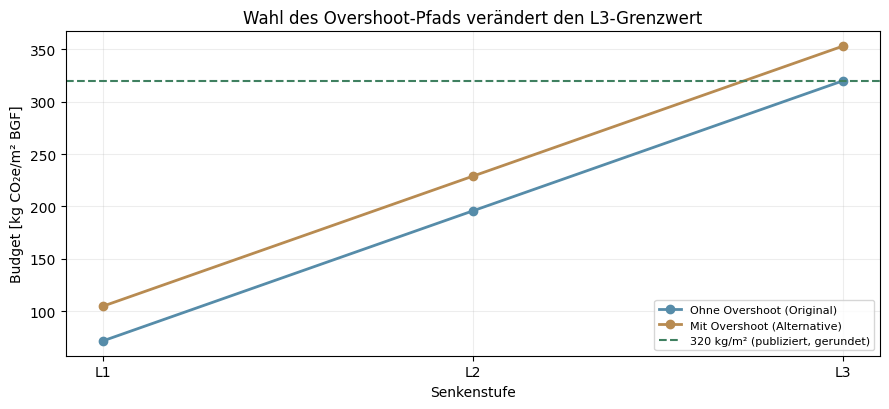

In [7]:
reference_id = 'STEIN2022_15_NO_66'
overshoot_id = 'STEIN2022_15_YES_66'
reference_cases = []
for budget_id in (reference_id, overshoot_id):
    for label,sink in SINK_LEVELS.items():
        res=calculate_scenario(budget_id,2025,sink,history_mode=REPRODUCTION_HISTORY)
        reference_cases.append({k:v for k,v in res.items() if k!='abzug_komponenten'}|{'level':label})
ref_table=pd.DataFrame(reference_cases)
display(ref_table[['budget_id','referenzjahr','bewertungsjahr','start_budget_Mt',
    'historical_deduction_Mt','remaining_CO2_budget_Mt','level','senken_t_cap_a',
    'additional_sinks_Mt','sector_budget_Mt','target_kgCO2e_m2_BGF']])
fig,ax=plt.subplots(figsize=(9,4.2))
for name,part,color in [('Ohne Overshoot (Original)',reference_id,'#568ca9'),
                         ('Mit Overshoot (Alternative)',overshoot_id,'#b88b51')]:
    sub=ref_table.loc[ref_table.budget_id==part].set_index('level').reindex(['L1','L2','L3'])
    ax.plot(sub.index,sub.target_kgCO2e_m2_BGF,marker='o',lw=2,label=name,color=color)
ax.axhline(320,color='#3f8060',ls='--',label='320 kg/m² (publiziert, gerundet)')
ax.set(xlabel='Senkenstufe',ylabel='Budget [kg CO₂e/m² BGF]',title='Wahl des Overshoot-Pfads verändert den L3-Grenzwert')
ax.legend(fontsize=8);plt.tight_layout();plt.show()

## 6. Rechnung B: Fortschreibung auf die Bewertungsjahre 2025 und 2026

Dieser Lauf verwendet **pro Budget** das zugeordnete Referenzjahr. Abzüge werden anschließend anhand der **Jahrestabelle** erhoben. Die Tabelle zeigt **auch dann beide Bewertungsjahre**, wenn ein für Österreich gültiges Lamboll-Budget oder eine CO₂-only-Emissionszahl fehlt. Der Fehlerstatus nennt den konkreten fehlenden Eintrag. Bei 2026 ist das vollständige Kalenderjahr 2025 abzuziehen; ein NowCast in *CO₂e* darf dafür nicht automatisch als *CO₂* umgedeutet werden.

In [8]:
COMPARE_BUDGET_IDS = [reference_id, overshoot_id, SELECTED_BUDGET_ID]
future_rows=[]
for bid in dict.fromkeys(COMPARE_BUDGET_IDS):
    for year in EVALUATION_YEARS:
        mode=REPRODUCTION_HISTORY if bid.startswith('STEIN') else MODERN_HISTORY
        try:
            rec=calculate_scenario(bid,year,SINK_LEVELS['L3'],mode)
            future_rows.append({'budget_id':bid,'bewertungsjahr':year,'referenzjahr':rec['referenzjahr'],
              'historischer_abzug_Mt':rec['historical_deduction_Mt'],
              'restbudget_Mt':rec['remaining_CO2_budget_Mt'],
              'L3_kgCO2e_m2_BGF':rec['target_kgCO2e_m2_BGF'],
              'senkenjahre':rec['jahre_senken'],'status':rec['hinweis']})
        except (HistoricalDataGap,ValueError) as err:
            future_rows.append({'budget_id':bid,'bewertungsjahr':year,
               'referenzjahr':int(budget_row(bid).referenzjahr),
               'historischer_abzug_Mt':np.nan,'restbudget_Mt':np.nan,
               'L3_kgCO2e_m2_BGF':np.nan,'senkenjahre':years_remaining(year),
               'status':str(err)})
comparison_years=pd.DataFrame(future_rows)
display(comparison_years)

,budget_id,bewertungsjahr,referenzjahr,historischer_abzug_Mt,restbudget_Mt,L3_kgCO2e_m2_BGF,senkenjahre,status
0,STEIN2022_15_NO_66,2025,2022,150.0,130.0,319.841182,50,rechenbar
1,STEIN2022_15_NO_66,2026,2022,NaN,NaN,NaN,49,CO₂-Jahresemissionen fehlen: Jahr 2025 (Zeile CO2_TERRITORIAL).
2,STEIN2022_15_YES_66,2025,2022,150.0,190.0,352.928201,50,rechenbar
3,STEIN2022_15_YES_66,2026,2022,NaN,NaN,NaN,49,CO₂-Jahresemissionen fehlen: Jahr 2025 (Zeile CO2_TERRITORIAL).
4,LAMBOLL2023_AT_20_66,2025,2023,NaN,NaN,NaN,50,Nationales AT-Budget fehlt für LAMBOLL2023_AT_20_66.
5,LAMBOLL2023_AT_20_66,2026,2023,NaN,NaN,NaN,49,Nationales AT-Budget fehlt für LAMBOLL2023_AT_20_66.


### 6.1 Verteilung des nationalen Budgets – jeder Rechenschritt offen

Eine Sankey- oder Dashboarddarstellung wird bewusst vermieden. Für die veröffentlichte 2025-Rechnung werden **Ausgangsbudget → historischer Abzug → verbleibendes CO₂-Budget → Senken → Sektoranteil → Bezugsfläche** tabellarisch und als Wasserfalldiagramm gezeigt. Die 2026-Version wird automatisch ergänzt, sobald die fehlenden Daten wissenschaftlich konsistent eingetragen sind.

,budget_id,schritt,wert_Mt,quelle
0,STEIN2022_15_NO_66,1 Ausgangsbudget ab Referenzjahr,280.0,S1-A1
1,STEIN2022_15_NO_66,2 Historisch emittiert,-150.0,S1-A1
2,STEIN2022_15_NO_66,3 Verbleibendes Budget,130.0,Berechnung
3,STEIN2022_15_NO_66,4 Zusätzliche Senken,450.0,S1-A1 / Annahme
4,STEIN2022_15_NO_66,5 National mit Senken,580.0,Berechnung
5,STEIN2022_15_NO_66,6 Sektorbudget (50 %),290.0,Berechnung
6,STEIN2022_15_YES_66,1 Ausgangsbudget ab Referenzjahr,340.0,S1-A1
7,STEIN2022_15_YES_66,2 Historisch emittiert,-150.0,S1-A1
8,STEIN2022_15_YES_66,3 Verbleibendes Budget,190.0,Berechnung
9,STEIN2022_15_YES_66,4 Zusätzliche Senken,450.0,S1-A1 / Annahme


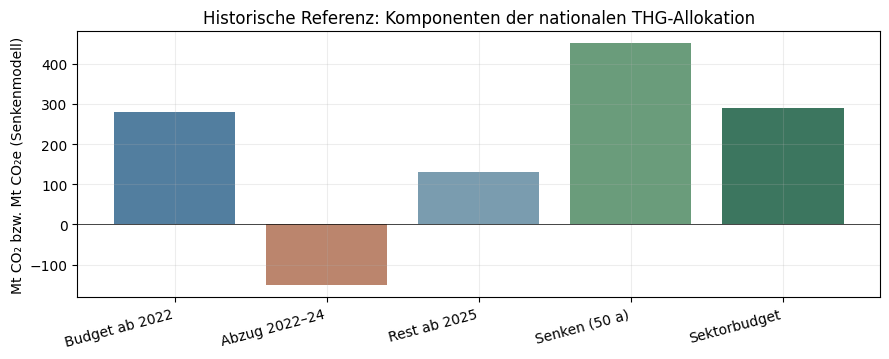

In [9]:
steps=[]
for bid in (reference_id,overshoot_id):
    rec=calculate_scenario(bid,2025,1.0,REPRODUCTION_HISTORY)
    steps += [dict(budget_id=bid,schritt='1 Ausgangsbudget ab Referenzjahr',wert_Mt=rec['start_budget_Mt'],quelle=rec['quelle']),
              dict(budget_id=bid,schritt='2 Historisch emittiert',wert_Mt=-rec['historical_deduction_Mt'],quelle='S1-A1'),
              dict(budget_id=bid,schritt='3 Verbleibendes Budget',wert_Mt=rec['remaining_CO2_budget_Mt'],quelle='Berechnung'),
              dict(budget_id=bid,schritt='4 Zusätzliche Senken',wert_Mt=rec['additional_sinks_Mt'],quelle='S1-A1 / Annahme'),
              dict(budget_id=bid,schritt='5 National mit Senken',wert_Mt=rec['national_with_sinks_Mt'],quelle='Berechnung'),
              dict(budget_id=bid,schritt='6 Sektorbudget (50 %)',wert_Mt=rec['sector_budget_Mt'],quelle='Berechnung')]
steps_table=pd.DataFrame(steps)
display(steps_table)
rec=calculate_scenario(reference_id,2025,1.0,REPRODUCTION_HISTORY)
fig, ax = plt.subplots(figsize=(9,3.7))
labels=['Budget ab 2022','Abzug 2022–24','Rest ab 2025','Senken (50 a)','Sektorbudget']
values=[rec['start_budget_Mt'],-rec['historical_deduction_Mt'],rec['remaining_CO2_budget_Mt'],
        rec['additional_sinks_Mt'],rec['sector_budget_Mt']]
ax.bar(labels,values,color=['#527e9f','#bb856d','#7a9caf','#6a9c7b','#3c765f'])
ax.axhline(0,color='black',lw=.5)
ax.set(ylabel='Mt CO₂ bzw. Mt CO₂e (Senkenmodell)',title='Historische Referenz: Komponenten der nationalen THG-Allokation')
plt.xticks(rotation=15,ha='right');plt.tight_layout();plt.show()

### 6.2 Wirkung des Bewertungsjahrs auf die Senkenannahme

Bei fixem Endjahr 2075 reduzieren sich die noch anzusetzenden Senkenjahre von 50 (ab 2025) auf 49 (ab 2026). Die nationale historische Emissionsbilanz wird unabhängig davon fortgeschrieben. Für alternative Untersuchungen kann `HORIZON_POLICY='rolling_50'` gesetzt werden. Diese Änderung betrifft die langfristige Bilanzannahme und muss im Ergebnisprotokoll ausdrücklich ausgewiesen bleiben.

In [10]:
sink_years=pd.DataFrame({'bewertungsjahr':EVALUATION_YEARS,
                         'senkenjahre':[years_remaining(y) for y in EVALUATION_YEARS]})
sink_years['senken_bei_1t_Mt']=POPULATION_MILLION*sink_years.senkenjahre
sink_years['methode']=HORIZON_POLICY
display(sink_years)

,bewertungsjahr,senkenjahre,senken_bei_1t_Mt,methode
0,2025,50,450.0,fixed_end
1,2026,49,441.0,fixed_end


## 7. Gebäudeflächen und Konsistenz der Bezugsfläche

Die Bestandsstände in S2 verwenden **unterschiedliche Modelle und Abgrenzungen**; ihre Differenzen sind kein Beleg für Zu- oder Abgang von Bestandsflächen. Die historische THG-Zuteilung basiert auf **906,7 Mio. m² BGF**; eine neue, sektoral harmonisierte Flächenzahl muss als gesonderte Rekalibrierung dokumentiert werden.

,datenstand,beschreibung,jahr,BGF_Mio_m2,NGF_Mio_m2,quelle,hinweis
0,statistik_2021,Statistikbezug / GFZ-Hochrechnung,2021,1058.935,847.100,S2,andere Abgrenzung
1,pool_today,"Building-Sector Pool, heute",offen,1112.341,889.873,S2,Typenflächen
2,pool_2040,"Building-Sector Pool, Entwicklung 2040",2040,1126.579,901.263,S2,keine automatische THG-Änderung
3,thg_reference,Zielbestand 2040 für THG-Allokation,2040,906.700,NaN,S1-A1,historische Kalibrierung


,beschreibung,BGF_Mio_m2,L3_kg_m2_bei_unveraendertem_Sektorbudget
0,Statistikbezug / GFZ-Hochrechnung,1058.935,273.860058
1,"Building-Sector Pool, heute",1112.341,260.711419
2,"Building-Sector Pool, Entwicklung 2040",1126.579,257.416479
3,Zielbestand 2040 für THG-Allokation,906.700,319.841182


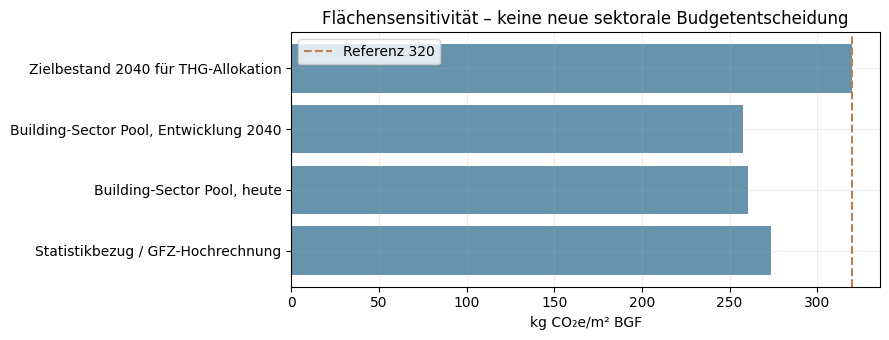

In [11]:
floor_areas=pd.DataFrame([
    ('statistik_2021','Statistikbezug / GFZ-Hochrechnung','2021',1058.935,847.1,'S2','andere Abgrenzung'),
    ('pool_today','Building-Sector Pool, heute','offen',1112.341,889.873,'S2','Typenflächen'),
    ('pool_2040','Building-Sector Pool, Entwicklung 2040','2040',1126.579,901.263,'S2','keine automatische THG-Änderung'),
    ('thg_reference','Zielbestand 2040 für THG-Allokation','2040',906.7,np.nan,'S1-A1','historische Kalibrierung'),
],columns=['datenstand','beschreibung','jahr','BGF_Mio_m2','NGF_Mio_m2','quelle','hinweis'])
display(floor_areas)
base=calculate_scenario(reference_id,2025,1.0,REPRODUCTION_HISTORY)
areas=floor_areas[['beschreibung','BGF_Mio_m2']].copy()
areas['L3_kg_m2_bei_unveraendertem_Sektorbudget']=1000*base['sector_budget_Mt']/areas.BGF_Mio_m2
display(areas)
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(areas.beschreibung,areas.L3_kg_m2_bei_unveraendertem_Sektorbudget,color='#6793ad')
ax.axvline(320,ls='--',color='#bd804f',label='Referenz 320')
ax.set(xlabel='kg CO₂e/m² BGF',title='Flächensensitivität – keine neue sektorale Budgetentscheidung')
ax.legend();plt.tight_layout();plt.show()

## 8. Dekarbonisierungsannahmen und Betrachtungszeitraum

Die nachfolgende **illustrative** Kurve dokumentiert die zeitliche Modellannahme aus S1, Abschn. 2.4/2.6, und ersetzt weder die in S2 zitierte Originalabbildung noch die fehlenden numerischen Trägerpfade. Strom und erneuerbare Fernwärme werden linear auf 0 bis 2050 abgeschätzt; eine solche Kurve ist von der hier berechneten nationalen CO₂-Budgetfortschreibung logisch getrennt. **2040** ist das nationale Klimaneutralitätsziel; **2050** der vorsorglich spätere Dekarbonisierungspunkt; **2075** das Ende der ursprünglichen 50-jährigen Quartiers-LCA.

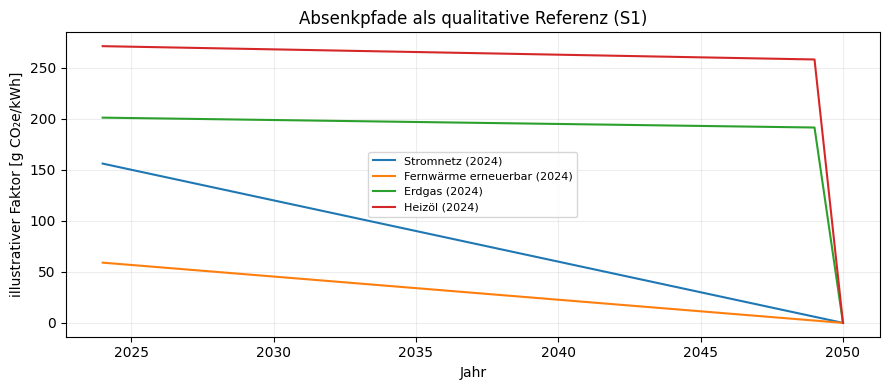

In [12]:
carrier_start={'Stromnetz (2024)':156,'Fernwärme erneuerbar (2024)':59,
               'Erdgas (2024)':201,'Heizöl (2024)':271}
fig,ax=plt.subplots(figsize=(9,4))
for name,g in carrier_start.items():
    yrs=np.arange(2024,2051)
    if 'Erdgas' in name or 'Heizöl' in name:
        path=np.where(yrs<2050,g*(1-.05*(yrs-2024)/26),0)
    else: path=g*np.maximum(0,(2050-yrs)/26)
    ax.plot(yrs,path,label=name)
ax.set(xlabel='Jahr',ylabel='illustrativer Faktor [g CO₂e/kWh]',title='Absenkpfade als qualitative Referenz (S1)')
ax.legend(fontsize=8);plt.tight_layout();plt.show()

## 9. Prüfungen, Szenariokompatibilität und Datenqualität

**Festgelegte Invarianten:** Budget-ID eindeutig, Referenzjahr vor Bewertungsjahr, Abzug in vollständigen Kalenderjahren und in `Mt CO₂`, historischer Aggregatabzug nicht doppelt zählen, nationale und globale Budgets getrennt halten, fehlende Jahreswerte führen zu einem **expliziten Datenstatus**. Negative Restbudgets dürfen nicht auf null gesetzt werden: sie zeigen Budgetüberschreitung und werden als solche gekennzeichnet.

In [13]:
# Originalberechnung 66 %, ohne Overshoot (exakte Publikationsreproduktion):
r=calculate_scenario(reference_id,2025,1.0,REPRODUCTION_HISTORY)
assert math.isclose(r['start_budget_Mt'],280)
assert math.isclose(r['historical_deduction_Mt'],150)
assert math.isclose(r['remaining_CO2_budget_Mt'],130)
assert math.isclose(r['additional_sinks_Mt'],450)
assert math.isclose(r['sector_budget_Mt'],290)
assert round(r['target_kgCO2e_m2_BGF'])==320
assert [round(calculate_scenario(reference_id,2025,s,REPRODUCTION_HISTORY)['target_kgCO2e_m2_BGF']) for s in (0,.5,1)] == [72,196,320]
# Overshoot 66 % ist eine eigenständige Variante:
o=calculate_scenario(overshoot_id,2025,1.0,REPRODUCTION_HISTORY)
assert math.isclose(o['remaining_CO2_budget_Mt'],190)
assert round(o['target_kgCO2e_m2_BGF'])==353
# Keine fälschliche Rückrechnung mit Gesamt-THG in CO2e:
try:
    historical_deduction(2022,2026,'CO2_TERRITORIAL')
except HistoricalDataGap as e:
    print('Erwartete Inventarlücke:',str(e))
else: print('CO2-only Jahre 2022–2025 sind nun vollständig hinterlegt.')
# Paper-Block plus fehlendes Jahr 2025: beim vorliegenden Datenstand blockiert.
try:
    historical_deduction(2022,2026,'S1_aggregat')
except HistoricalDataGap as e:
    print('Erwarteter 2026-Nachtrag:',str(e))
else: print('2026-Datenlücke geschlossen – Wert für 2025 mit Quelle prüfen.')
assert budgets.loc[budgets.budget_id.str.startswith('LAMBOLL'),'national_budget_Mt'].isna().all() or        budgets.loc[budgets.budget_id.str.startswith('LAMBOLL') & budgets.national_budget_Mt.notna(),'quelle_id'].notna().all()
assert not history.duplicated(['jahr','reihe']).any()
print('✓ Referenzrechnung und methodische Schutzprüfungen abgeschlossen.')

Erwartete Inventarlücke: CO₂-Jahresemissionen fehlen: Jahr 2022 (Zeile CO2_TERRITORIAL).
Erwarteter 2026-Nachtrag: CO₂-Jahresemissionen fehlen: Jahr 2025 (Zeile CO2_TERRITORIAL).
✓ Referenzrechnung und methodische Schutzprüfungen abgeschlossen.


## 10. FAIR-Export und maschinenlesbare Provenienz

Die Ausgabe kann als CSV/JSON exportiert werden. Sie enthält Budget-IDs, Ausgangsjahre, Abzugsreihen, Bewertungen, Senkenjahre, Quelle und Datenstatus. **Veränderungen an externen CSV-Dateien werden per SHA-256 dokumentiert.** `EXPORT_OUTPUTS=True` schreibt nur die hier explizit ausgewerteten Rechenstände und lässt unvollständige Daten als fehlende Werte bestehen. Für Publikation zusätzlich Datumsstand, Rechte und die nationale Lamboll-Allokationsmethode dokumentieren.

In [14]:
EXPORT_OUTPUTS = False

def sha256_file(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):
            h.update(block)
    return h.hexdigest()

if EXPORT_OUTPUTS:
    out=Path('THG_outputs');out.mkdir(exist_ok=True)
    objects={'national_budget_scenarios.csv':budgets,
             'historische_emissionen_AT.csv':history,
             'historische_aggregatannahmen.csv':aggregates,
             'globale_budgets_nur_kontext.csv':global_budgets,
             'rechenweg_original.csv':steps_table,
             'bewertungsjahre_2025_2026.csv':comparison_years,
             'gebaeudeflaechen.csv':floor_areas}
    for name,frame in objects.items():frame.to_csv(out/name,index=False,encoding='utf-8-sig')
    inputs={name:sha256_file(Path(name)) for name in (
          'thg_nationale_klimabudgets.csv','thg_historische_emissionen_AT.csv',
          'thg_historische_aggregatannahmen.csv','thg_globale_budgets_kontext.csv')
          if Path(name).exists()}
    manifest={'method_version':MODEL_VERSION,'created_utc':datetime.now(timezone.utc).isoformat(),
              'selected_budget_id':SELECTED_BUDGET_ID,'evaluation_years':EVALUATION_YEARS,
              'horizon_policy':HORIZON_POLICY,'assessment_end_year':ASSESSMENT_END_YEAR,
              'historical_mode':REPRODUCTION_HISTORY,'modern_mode':MODERN_HISTORY,
              'parameters':{'population_M':POPULATION_MILLION,'share':SECTOR_SHARE,
                            'GFA_Mm2':REFERENCE_GFA_MILLION_M2,'sink_levels':SINK_LEVELS},
              'sha256_inputs':inputs,'sources':SOURCE_URLS,
              'notes':['CO2 und CO2e werden für Budgetabzüge nicht vermischt',
                       'Steininger S1 historischer Abzug nur aggregiert',
                       'Lamboll nationaler Wert und CO2-only-Inventarjahre nachzutragen']}
    (out/'rechenlauf_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    print('FAIR-Datenexport:',out.resolve())
else:
    print('FAIR-Export deaktiviert. EXPORT_OUTPUTS=True aktivieren.')

FAIR-Export deaktiviert. EXPORT_OUTPUTS=True aktivieren.


## 11. Ergebnis und offene Daten für die Neukalibrierung

Die historische Rechnung kann bereits **vollständig** reproduziert werden: Das publizierte L3-Limit beträgt gerundet **320 kg CO₂e/m² BGF**, sofern 1,5 °C / 66 % **ohne** Overshoot, das nationale Budget von **280 Mt ab 2022**, der pauschale Abzug von **150 Mt bis zum 01.01.2025**, 50 Senkenjahre, 50 % Sektoranteil sowie 906,7 Mio. m² BGF verwendet werden. Dieselbe Rechnung **mit** Overshoot liefert **353 kg/m²** und darf nicht als die publizierte 320er-Herleitung bezeichnet werden.

Für die **Neuberechnung auf den 01.01.2026** fehlen noch die für denselben CO₂-Budgetbegriff geeigneten **Jahreswerte bis 2025**; die amtlich vorhandenen Gesamt-THG-Werte in CO₂e werden in der Quellen-Tabelle gezeigt, aber nicht stillschweigend abgezogen. Der **Lamboll-2023-Lauf** benötigt zusätzlich ein Österreich zugeordnetes CO₂-Budget ab **2023**, einschließlich Wahrscheinlichkeit, Allokationsprinzip und Quellenangabe. Sobald diese CSV-Felder ergänzt sind, werden **2025 und 2026** mit demselben Code berechnet.

**Weitere Interpretationsgrenzen:** Zeitliche Senkenkonvention; Wechsel zwischen CO₂-Budget und THG-LCA; nationaler vs. projektbezogener Senkennachweis; Zuordnung der grauen PV-Emissionen; Harmonisierung der BGF; Unsicherheit und Revision der nationalen Inventur. Eine abweichende Neukalibrierung ist mit Daten- und Methodenstand zu kennzeichnen.